
# Persistent structure-based KMC benchmark for experimental protein–ligand holo complexes

This notebook benchmarks a coarse-grained kinetic Monte Carlo model against
association rates derived from experimental \(k_{\mathrm{off}}\) and \(K_D\):

\[
k_{\mathrm{on}}=\frac{k_{\mathrm{off}}}{K_D}.
\]

The original table contains 11 experimental holo entries. The current
single-component ligand preparation supports 10 directly. PDB 5A3O is retained
in the source table but excluded automatically because its experimental ligand
is represented as multiple PDB chemical components.

## Persistent execution

Every completed complex is saved immediately to Google Drive:

- one JSON checkpoint per complex;
- one trajectory CSV per complex;
- continuously rebuilt combined result and failure tables.

After a Colab disconnection, rerun the notebook cells and the benchmark cell.
Completed complexes are skipped, an interrupted `running` complex is rerun,
and execution continues with the next unfinished complex.


In [ ]:
%pip -q install rdkit biopython gemmi scipy scikit-learn pandas numpy matplotlib requests tqdm pyarrow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 111.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 161.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 156.2 MB/s eta 0:00:00


In [ ]:
%pip install gemmi
%pip install biopython
%pip install rdkit

import os
import re
import json
import math
import time
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import gemmi

from tqdm.auto import tqdm
from scipy.spatial import cKDTree
from scipy.spatial.transform import Rotation
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error

from Bio.PDB.MMCIF2Dict import MMCIF2Dict

from rdkit import Chem, RDConfig, RDLogger
from rdkit.Chem import AllChem, ChemicalFeatures

RDLogger.DisableLog("rdApp.warning")
warnings.filterwarnings("ignore", category=RuntimeWarning)

SEED = 20260719
np.random.seed(SEED)

# ------------------------------------------------------------
# Mount Google Drive
# ------------------------------------------------------------

try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    print("Not running in Google Colab; using /mnt/data for persistence.")

# ------------------------------------------------------------
# Persistent and local directories
# ------------------------------------------------------------

if Path("/content/drive/MyDrive").exists():
    DRIVE_ROOT = Path("/content/drive/MyDrive/KMC_experimental_holo_benchmark")
else:
    DRIVE_ROOT = Path("/mnt/data/KMC_experimental_holo_benchmark")

# Persistent folders survive a Colab disconnect.
DRIVE_CHECKPOINTS = DRIVE_ROOT / "checkpoints"
DRIVE_TRAJECTORIES = DRIVE_ROOT / "trajectories"
OUTPUTS = DRIVE_ROOT / "outputs"

# Structures and CCD files can be redownloaded, but storing them on Drive
# also avoids repeated downloads after a new runtime starts.
STRUCTURES = DRIVE_ROOT / "structures"
CCD = DRIVE_ROOT / "ccd"

for folder in [
    DRIVE_ROOT,
    DRIVE_CHECKPOINTS,
    DRIVE_TRAJECTORIES,
    OUTPUTS,
    STRUCTURES,
    CCD,
]:
    folder.mkdir(parents=True, exist_ok=True)

ROOT = DRIVE_ROOT
CHECKPOINTS = DRIVE_CHECKPOINTS

print("Persistent project directory:", DRIVE_ROOT)


Mounted at /content/drive
Persistent project directory: /content/drive/MyDrive/KMC_experimental_holo_benchmark


## 1. Configuration

In [ ]:

# -------------------------
# Execution mode
# -------------------------

FAST_MODE = False

if FAST_MODE:
    N_TRAJECTORIES = 8
    MAX_STEPS = 1500
else:
    N_TRAJECTORIES = 1000
    MAX_STEPS = 10000

# -------------------------
# Resume behavior
# -------------------------

# Skip a complex whose persistent checkpoint has status="ok".
RESUME_COMPLETED = True

# Retry a complex whose persistent checkpoint has status="failed".
RETRY_FAILED = True

# Rebuild combined result files after every completed or failed complex.
SAVE_COMBINED_TABLES_AFTER_EACH_COMPLEX = True

# -------------------------
# Geometry and state definitions
# -------------------------

POCKET_RADIUS_A = 7.0
START_RADIUS_A = 28.0
OUTER_RADIUS_A = 38.0

ENCOUNTER_DISTANCE_A = 6.0
POCKET_ENTRY_COM_A = 7.0
BOUND_RMSD_A = 3.0
BOUND_CONTACT_FRACTION = 0.40
BOUND_PERSISTENCE = 5

# -------------------------
# Monte Carlo proposal moves
# -------------------------

TRANSLATION_SIGMA_A = 0.60
ROTATION_SIGMA_DEG = 10.0
TORSION_SIGMA_DEG = 22.0
MOVE_PROBS = {
    "translate": 0.60,
    "rotate": 0.27,
    "torsion": 0.13,
}

# -------------------------
# Physical conditions
# -------------------------

TEMPERATURE_K = 298.15
IONIC_STRENGTH_M = 0.15
DIELECTRIC = 78.5
LIGAND_DIFFUSION_A2_PER_NS = 50.0

# -------------------------
# Network and cache
# -------------------------

HTTP_TIMEOUT = 120
REQUEST_DELAY = 0.10
RESUME_DOWNLOADS = True

print({
    "fast_mode": FAST_MODE,
    "trajectories_per_complex": N_TRAJECTORIES,
    "maximum_steps": MAX_STEPS,
    "resume_completed": RESUME_COMPLETED,
    "retry_failed": RETRY_FAILED,
})


{'fast_mode': False, 'trajectories_per_complex': 1000, 'maximum_steps': 10000, 'resume_completed': True, 'retry_failed': True}


## 2. Embedded 11-complex experimental test set

In [ ]:

# These values were extracted from the Experimental_Holo_PDB worksheet.
# The experimental kon values are derived from koff / Kd.

TEST_SET = [
    dict(pdb_id='1KV1', uniprot='Q16539', target='p38 alpha',
         koff_s_1=0.062, kd_nM=1160.0,
         smiles='Cn1nc(C(C)(C)C)cc1NC(=O)Nc1ccc(Cl)cc1',
         inchikey='FWIJKWMXNHRSRO-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='3QRI', uniprot='P00519', target='ABL1',
         koff_s_1=2.95e-5, kd_nM=7.2,
         smiles='CNC(=O)c1cc(Oc2ccc(NC(=O)Nc3cc(C(C)(C)C)nn3-c3ccc4ncccc4c3)c(F)c2)ccn1',
         inchikey='WVXNSAVVKYZVOE-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='3QRJ', uniprot='P00519', target='ABL1',
         koff_s_1=2.15e-5, kd_nM=7.2,
         smiles='CNC(=O)c1cc(Oc2ccc(NC(=O)Nc3cc(C(C)(C)C)nn3-c3ccc4ncccc4c3)c(F)c2)ccn1',
         inchikey='WVXNSAVVKYZVOE-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='4LY1', uniprot='Q92769', target='HDAC2',
         koff_s_1=1.38e-5, kd_nM=55.2,
         smiles='CC(=O)Nc1ccc(C(=O)Nc2cc(-c3cccs3)ccc2N)cc1',
         inchikey='ABZSPJVXTTUFAA-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='3F3V', uniprot='P00523', target='Src kinase',
         koff_s_1=0.0115, kd_nM=73.0,
         smiles='Cc1cccc(-n2nc(C(C)(C)C)cc2NC(=O)Nc2ccc(Nc3ncnc4ccc(N)cc34)cc2)c1',
         inchikey='ZKESOLNZMJUNTF-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='4YX4', uniprot='P00918', target='Carbonic anhydrase II',
         koff_s_1=0.163, kd_nM=660.0,
         smiles='NS(=O)(=O)c1ccccc1',
         inchikey='KHBQMWCZKVMBLN-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='3PWH', uniprot='P29274', target='A2A adenosine receptor',
         koff_s_1=2.33e-4, kd_nM=0.22,
         smiles='Nc1nc(NCCc2ccc(O)cc2)nc2nc(-c3ccco3)nn12',
         inchikey='PWTBZOIUWZOPFT-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='5FCK', uniprot='P00746', target='Complement factor D',
         koff_s_1=0.0102, kd_nM=6.29,
         smiles='CC(NC(=O)C1CC2CC2N1C(=O)Cn1nc(C(N)=O)c2ccncc21)c1cccc(Cl)c1F',
         inchikey='YAALCKJNOOFODD-SKNMWMDOSA-N', match_type='connectivity'),
    dict(pdb_id='5A3O', uniprot='Q9HYN5', target='LecB lectin',
         koff_s_1=0.00183, kd_nM=18500.0,
         smiles='COC1OC(CNC(=O)C=Cc2ccccc2)C(O)C(O)C1O',
         inchikey='LHFOPICMJLPBDI-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='3LDP', uniprot='P11021', target='Glucose-regulated protein',
         koff_s_1=0.4, kd_nM=2410.0,
         smiles='Nc1ncnc2c1nc(NCc1ccc3ccccc3n1)n2C1OC(CO)C(O)C1O',
         inchikey='NAHSCHKAPXMNFP-UHFFFAOYSA-N', match_type='exact'),
    dict(pdb_id='5LWM', uniprot='P52333', target='JAK3',
         koff_s_1=3.30e-4, kd_nM=1.34,
         smiles='CN(C)C(=O)C(C#N)=Cc1ccc(-c2nc3cnc4[nH]ccc4c3n2C2CCCCC2)o1',
         inchikey='GJMZWYLOARVASY-NTCAYCPXSA-N', match_type='connectivity'),
]

test_set = pd.DataFrame(TEST_SET)
test_set['kd_M'] = test_set['kd_nM'] * 1e-9
test_set['kon_exp'] = test_set['koff_s_1'] / test_set['kd_M']
test_set['log10_kon_exp'] = np.log10(test_set['kon_exp'])
test_set['connkey'] = test_set['inchikey'].str.split('-').str[0]
test_set['complex_id'] = ['KMC11_%02d' % (i + 1) for i in range(len(test_set))]

test_set.to_csv(OUTPUTS / 'experimental_test_set_11.csv', index=False)
display(test_set[['complex_id','pdb_id','target','uniprot','koff_s_1','kd_nM','kon_exp','match_type']])


,complex_id,pdb_id,target,uniprot,koff_s_1,kd_nM,kon_exp,match_type
0,KMC11_01,1KV1,p38 alpha,Q16539,0.062000,1160.00,5.344828e+04,exact
1,KMC11_02,3QRI,ABL1,P00519,0.000029,7.20,4.097222e+03,exact
2,KMC11_03,3QRJ,ABL1,P00519,0.000022,7.20,2.986111e+03,exact
3,KMC11_04,4LY1,HDAC2,Q92769,0.000014,55.20,2.500000e+02,exact
4,KMC11_05,3F3V,Src kinase,P00523,0.011500,73.00,1.575342e+05,exact
5,KMC11_06,4YX4,Carbonic anhydrase II,P00918,0.163000,660.00,2.469697e+05,exact
6,KMC11_07,3PWH,A2A adenosine receptor,P29274,0.000233,0.22,1.059091e+06,exact
7,KMC11_08,5FCK,Complement factor D,P00746,0.010200,6.29,1.621622e+06,connectivity
8,KMC11_09,5A3O,LecB lectin,Q9HYN5,0.001830,18500.00,9.891892e+01,exact
9,KMC11_10,3LDP,Glucose-regulated protein,P11021,0.400000,2410.00,1.659751e+05,exact


## 3. Download PDB and CCD files, then identify the native ligand

In [ ]:
session = requests.Session()
session.headers.update({
    "User-Agent": "KMC-experimental-holo-benchmark/1.2 academic research"
})

EXCLUDED_COMPONENTS = {
    "HOH","WAT","DOD","SO4","PO4","GOL","EDO","PEG","PGE","PG4","MPD",
    "ACT","FMT","ACE","TRS","MES","HEP","CL","BR","IOD","NA","K","CA",
    "MG","MN","ZN","FE","CU","CO","NI",
}

STANDARD_AA = {
    "ALA","ARG","ASN","ASP","CYS","GLN","GLU","GLY","HIS","ILE","LEU",
    "LYS","MET","PHE","PRO","SER","THR","TRP","TYR","VAL",
}


def download_file(url, path, overwrite=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    if (
        not overwrite
        and RESUME_DOWNLOADS
        and path.exists()
        and path.stat().st_size > 0
    ):
        return path

    response = session.get(url, timeout=HTTP_TIMEOUT)

    if response.status_code == 404:
        raise FileNotFoundError(f"Remote file not found: {url}")

    response.raise_for_status()

    content_type = response.headers.get("content-type", "").lower()
    if "text/html" in content_type:
        raise RuntimeError(f"Received HTML instead of the requested file: {url}")

    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_bytes(response.content)

    if temporary.stat().st_size == 0:
        temporary.unlink(missing_ok=True)
        raise RuntimeError(f"Downloaded file is empty: {url}")

    temporary.replace(path)
    time.sleep(REQUEST_DELAY)
    return path


def get_pdb_cif(pdb_id, overwrite=False):
    pdb_id = str(pdb_id).strip().upper()
    return download_file(
        f"https://files.rcsb.org/download/{pdb_id}.cif",
        STRUCTURES / f"{pdb_id}.cif",
        overwrite=overwrite,
    )


def get_ccd_cif(component, overwrite=False):
    component = str(component).strip().upper()
    return download_file(
        f"https://files.rcsb.org/ligands/download/{component}.cif",
        CCD / f"{component}.cif",
        overwrite=overwrite,
    )


def get_ccd_sdf(component, overwrite=False):
    component = str(component).strip().upper()
    return download_file(
        f"https://files.rcsb.org/ligands/download/{component}_ideal.sdf",
        CCD / f"{component}_ideal.sdf",
        overwrite=overwrite,
    )


CCD_IDENTITY_CACHE = {}


def ccd_identity(component):
    component = str(component).strip().upper()

    if component in CCD_IDENTITY_CACHE:
        return CCD_IDENTITY_CACHE[component]

    try:
        sdf_path = get_ccd_sdf(component)
        supplier = Chem.SDMolSupplier(
            str(sdf_path),
            removeHs=False,
            sanitize=True,
        )
        mol = supplier[0] if len(supplier) else None

        if mol is None:
            CCD_IDENTITY_CACHE[component] = None
            return None

        mol = Chem.RemoveHs(mol)
        inchikey = Chem.MolToInchiKey(mol)

        identity = {
            "component": component,
            "inchikey": inchikey,
            "connkey": inchikey.split("-")[0] if inchikey else "",
            "mol": mol,
        }
        CCD_IDENTITY_CACHE[component] = identity
        return identity

    except Exception:
        CCD_IDENTITY_CACHE[component] = None
        return None


def structure_inventory(pdb_id):
    cif_path = get_pdb_cif(pdb_id)
    structure = gemmi.read_structure(str(cif_path))
    structure.setup_entities()

    if len(structure) == 0:
        raise ValueError(f"{pdb_id}: no coordinate models")

    model = structure[0]
    protein_atoms = []
    ligands = []

    for chain in model:
        for residue in chain:
            atoms = [atom for atom in residue if atom.element.name != "H"]
            if not atoms:
                continue

            component = residue.name.strip().upper()

            if residue.entity_type == gemmi.EntityType.Polymer:
                protein_atoms.extend(atom.pos.tolist() for atom in atoms)

            elif component not in EXCLUDED_COMPONENTS:
                ligands.append({
                    "component": component,
                    "chain": chain.name,
                    "seqid": str(residue.seqid),
                    "atom_names": [atom.name.strip() for atom in atoms],
                    "elements": [atom.element.name for atom in atoms],
                    "xyz": np.asarray(
                        [atom.pos.tolist() for atom in atoms],
                        dtype=float,
                    ),
                })

    protein_xyz = np.asarray(protein_atoms, dtype=float)
    if protein_xyz.ndim != 2 or protein_xyz.shape[1] != 3 or len(protein_xyz) == 0:
        raise ValueError(f"{pdb_id}: no protein heavy atoms")

    return cif_path, protein_xyz, ligands


def identify_native_ligand(row):
    cif_path, protein_xyz, ligands = structure_inventory(row.pdb_id)
    tree = cKDTree(protein_xyz)

    exact_candidates = []
    connectivity_candidates = []
    diagnostics = []

    for ligand in ligands:
        identity = ccd_identity(ligand["component"])

        if identity is None:
            diagnostics.append({
                "component": ligand["component"],
                "status": "CCD identity unavailable",
            })
            continue

        exact = identity["inchikey"] == row.inchikey
        connectivity = identity["connkey"] == row.connkey

        diagnostics.append({
            "component": ligand["component"],
            "ccd_inchikey": identity["inchikey"],
            "exact": exact,
            "connectivity": connectivity,
        })

        if not connectivity:
            continue

        nearest = tree.query(ligand["xyz"], k=1)[0]
        minimum_distance = float(np.min(nearest))
        if minimum_distance > 4.5:
            continue

        candidate = {
            **ligand,
            "cif_path": str(cif_path),
            "ccd_inchikey": identity["inchikey"],
            "ccd_connkey": identity["connkey"],
            "exact_stereo": exact,
            "nearest_protein_A": minimum_distance,
            "actual_match_type": "exact" if exact else "connectivity",
        }

        if exact:
            exact_candidates.append(candidate)
        else:
            connectivity_candidates.append(candidate)

    if exact_candidates:
        candidates = exact_candidates
    elif connectivity_candidates:
        candidates = connectivity_candidates
        print(
            f"WARNING: {row.pdb_id} uses connectivity matching because "
            "the test-set stereochemistry does not fully match the CCD InChIKey."
        )
    else:
        available = sorted(set(item["component"] for item in ligands))
        raise ValueError(
            f"{row.pdb_id}: no ligand matching {row.inchikey}; "
            f"query connectivity={row.connkey}; "
            f"available components={available}; diagnostics={diagnostics}"
        )

    candidates.sort(
        key=lambda item: (
            item["nearest_protein_A"],
            -len(item["xyz"]),
        )
    )
    return candidates[0]


# Filter the test set to exclude PDB 5A3O as per problem description.
test_set_kmc = test_set[test_set['pdb_id'] != '5A3O'].reset_index(drop=True)

identified_rows = []
identification_failures = []

for _, row in tqdm(
    test_set_kmc.iterrows(),
    total=len(test_set_kmc),
    desc="Identify native ligands",
):
    try:
        ligand = identify_native_ligand(row)
        identified_rows.append({
            "complex_id": row.complex_id,
            "pdb_id": row.pdb_id,
            "component": ligand["component"],
            "ligand_chain": ligand["chain"],
            "ligand_seqid": ligand["seqid"],
            "actual_match_type": ligand["actual_match_type"],
            "exact_stereo": ligand["exact_stereo"],
            "nearest_protein_A": ligand["nearest_protein_A"],
            "cif_path": ligand["cif_path"],
        })
    except Exception as exc:
        identification_failures.append({
            "complex_id": row.complex_id,
            "pdb_id": row.pdb_id,
            "error": repr(exc),
        })

identified = pd.DataFrame(identified_rows)
id_failures = pd.DataFrame(identification_failures)

identified.to_csv(
    OUTPUTS / "identified_native_ligands.csv",
    index=False,
)
id_failures.to_csv(
    OUTPUTS / "native_ligand_identification_failures.csv",
    index=False,
)

identified_ids = set(identified["complex_id"].astype(str)) if len(identified) else set()

run_set = (
    test_set_kmc[
        test_set_kmc["complex_id"].astype(str).isin(identified_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

excluded_identification = (
    test_set_kmc[
        ~test_set_kmc["complex_id"].astype(str).isin(identified_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

print("Native ligands identified:", len(identified))
print("Identification failures:", len(id_failures))
print("Runnable KMC systems:", len(run_set))

if len(identified):
    display(identified)
if len(id_failures):
    display(id_failures)


Identify native ligands:   0%|          | 0/10 [00:00<?, ?it/s]

Native ligands identified: 10
Identification failures: 0
Runnable KMC systems: 10


,complex_id,pdb_id,component,ligand_chain,ligand_seqid,actual_match_type,exact_stereo,nearest_protein_A,cif_path
0,KMC11_01,1KV1,BMU,A,391,exact,True,2.757459,/content/drive/MyDrive/KMC_experimental_holo_b...
1,KMC11_02,3QRI,919,B,2,exact,True,2.674419,/content/drive/MyDrive/KMC_experimental_holo_b...
2,KMC11_03,3QRJ,919,A,2,exact,True,2.755604,/content/drive/MyDrive/KMC_experimental_holo_b...
3,KMC11_04,4LY1,20Y,B,408,exact,True,2.605216,/content/drive/MyDrive/KMC_experimental_holo_b...
4,KMC11_05,3F3V,1BU,A,1,exact,True,2.429409,/content/drive/MyDrive/KMC_experimental_holo_b...
5,KMC11_06,4YX4,FB2,A,303,exact,True,2.812503,/content/drive/MyDrive/KMC_experimental_holo_b...
6,KMC11_07,3PWH,ZMA,A,401,exact,True,3.060803,/content/drive/MyDrive/KMC_experimental_holo_b...
7,KMC11_08,5FCK,5WC,A,301,exact,True,2.720140,/content/drive/MyDrive/KMC_experimental_holo_b...
8,KMC11_10,3LDP,3P1,B,502,connectivity,False,2.440871,/content/drive/MyDrive/KMC_experimental_holo_b...
9,KMC11_11,5LWM,79T,A,1201,connectivity,False,2.808000,/content/drive/MyDrive/KMC_experimental_holo_b...


## 4. Build a chemically typed ligand directly from the CCD CIF

In [ ]:

BOND_TYPES = {
    'SING': Chem.BondType.SINGLE,
    'DOUB': Chem.BondType.DOUBLE,
    'TRIP': Chem.BondType.TRIPLE,
    'AROM': Chem.BondType.AROMATIC,
    'DELO': Chem.BondType.AROMATIC,
}


def as_list(value):
    if isinstance(value, list):
        return value
    return [value]


def ccd_mol_with_atom_names(component):
    """Construct an RDKit molecule from CCD atom and bond tables.

    Atom names are retained as the `ccd_atom_id` property, allowing exact mapping
    to the atom names in the experimental PDB ligand residue.
    """
    cif_path = get_ccd_cif(component)
    data = MMCIF2Dict(str(cif_path))

    atom_ids = as_list(data['_chem_comp_atom.atom_id'])
    symbols = as_list(data['_chem_comp_atom.type_symbol'])
    charges = as_list(data.get('_chem_comp_atom.charge', ['0'] * len(atom_ids)))

    rw = Chem.RWMol()
    atom_index = {}
    for atom_id, symbol, charge in zip(atom_ids, symbols, charges):
        if str(symbol).upper() in {'H', 'D'}:
            continue
        atom = Chem.Atom(str(symbol).title())
        try:
            atom.SetFormalCharge(int(float(charge)))
        except Exception:
            pass
        atom.SetProp('ccd_atom_id', str(atom_id).strip())
        idx = rw.AddAtom(atom)
        atom_index[str(atom_id).strip()] = idx

    bond_a = as_list(data.get('_chem_comp_bond.atom_id_1', []))
    bond_b = as_list(data.get('_chem_comp_bond.atom_id_2', []))
    bond_order = as_list(data.get('_chem_comp_bond.value_order', []))

    for a, b, order in zip(bond_a, bond_b, bond_order):
        a = str(a).strip(); b = str(b).strip()
        if a not in atom_index or b not in atom_index:
            continue
        bt = BOND_TYPES.get(str(order).upper(), Chem.BondType.SINGLE)
        if rw.GetBondBetweenAtoms(atom_index[a], atom_index[b]) is None:
            rw.AddBond(atom_index[a], atom_index[b], bt)

    mol = rw.GetMol()
    try:
        Chem.SanitizeMol(mol)
    except Exception:
        # Some CCD entries need aromaticity cleanup; use a reduced sanitization pass.
        Chem.SanitizeMol(
            mol,
            sanitizeOps=(
                Chem.SanitizeFlags.SANITIZE_FINDRADICALS |
                Chem.SanitizeFlags.SANITIZE_KEKULIZE |
                Chem.SanitizeFlags.SANITIZE_SETAROMATICITY |
                Chem.SanitizeFlags.SANITIZE_SETCONJUGATION |
                Chem.SanitizeFlags.SANITIZE_SETHYBRIDIZATION |
                Chem.SanitizeFlags.SANITIZE_SYMMRINGS
            )
        )
    return mol


def attach_experimental_coordinates(mol, atom_names, xyz):
    coord_by_name = {
        str(name).strip(): np.asarray(pos, dtype=float)
        for name, pos in zip(atom_names, xyz)
    }
    conf = Chem.Conformer(mol.GetNumAtoms())
    missing = []
    for atom in mol.GetAtoms():
        name = atom.GetProp('ccd_atom_id')
        if name not in coord_by_name:
            missing.append(name)
            continue
        conf.SetAtomPosition(atom.GetIdx(), tuple(coord_by_name[name]))
    if missing:
        raise ValueError(f'CCD/PDB atom-name mapping failed; missing={missing}')
    mol.RemoveAllConformers()
    mol.AddConformer(conf)
    return mol


## 5. Prepare the coarse-grained protein–ligand systems

In [ ]:

RES_Q = {'ASP':-1.0,'GLU':-1.0,'LYS':1.0,'ARG':1.0,'HIS':0.1}
RES_H = {
    'ILE':1.0,'LEU':1.0,'VAL':0.9,'PHE':1.0,'TRP':1.0,'MET':0.8,
    'ALA':0.6,'PRO':0.5,'TYR':0.4,'CYS':0.4,'THR':-0.1,'SER':-0.2,
    'GLY':-0.2,'HIS':-0.2,'ASN':-0.5,'GLN':-0.5,'LYS':-0.7,
    'ARG':-0.8,'ASP':-1.0,'GLU':-1.0
}
DONOR_RES = {'ARG','LYS','HIS','ASN','GLN','SER','THR','TYR','TRP'}
ACCEPTOR_RES = {'ASP','GLU','ASN','GLN','HIS','SER','THR','TYR'}

factory = ChemicalFeatures.BuildFeatureFactory(
    os.path.join(RDConfig.RDDataDir, 'BaseFeatures.fdef')
)
ROT_SMARTS = Chem.MolFromSmarts('[!$(*#*)&!D1]-&!@[!$(*#*)&!D1]')


def prepare_system(row):
    match = identified.loc[identified.complex_id == row.complex_id]
    if len(match) != 1:
        raise ValueError('No unique identified ligand for this complex')
    match = match.iloc[0]

    structure = gemmi.read_structure(str(get_pdb_cif(row.pdb_id)))
    structure.setup_entities()
    model = structure[0]

    protein_atoms = []
    residues = []
    ligand_record = None

    for chain in model:
        for residue in chain:
            atoms = [atom for atom in residue if atom.element.name != 'H']
            if not atoms:
                continue
            if residue.entity_type == gemmi.EntityType.Polymer and residue.name.upper() in STANDARD_AA:
                xyz = np.asarray([atom.pos.tolist() for atom in atoms], dtype=float)
                protein_atoms.extend(xyz)
                residues.append((chain.name, residue, xyz))
            elif (
                residue.name.upper() == match.component
                and chain.name == match.ligand_chain
                and str(residue.seqid) == str(match.ligand_seqid)
            ):
                ligand_record = {
                    'atom_names': [atom.name.strip() for atom in atoms],
                    'xyz': np.asarray([atom.pos.tolist() for atom in atoms], dtype=float),
                }

    if ligand_record is None:
        raise ValueError('The selected ligand instance was not found in the PDB file')

    protein_atoms = np.asarray(protein_atoms, dtype=float)
    if len(protein_atoms) == 0:
        raise ValueError('No protein heavy atoms found')

    mol = ccd_mol_with_atom_names(match.component)
    mol = attach_experimental_coordinates(
        mol, ligand_record['atom_names'], ligand_record['xyz']
    )
    AllChem.ComputeGasteigerCharges(mol)
    ligand_xyz = np.asarray(mol.GetConformer().GetPositions(), dtype=float)

    # Pocket residues are defined around the native ligand pose.
    pocket = []
    for chain_name, residue, residue_xyz in residues:
        distance = np.linalg.norm(
            residue_xyz[:, None, :] - ligand_xyz[None, :, :], axis=2
        ).min()
        if distance > POCKET_RADIUS_A:
            continue

        atom_map = {
            atom.name.strip(): atom
            for atom in residue if atom.element.name != 'H'
        }
        residue_name = residue.name.upper()

        if 'CA' in atom_map:
            pocket.append({
                'xyz': np.asarray(atom_map['CA'].pos.tolist(), dtype=float),
                'q': 0.0, 'h': -0.1, 'donor': False, 'acceptor': True,
            })

        sidechain = [
            atom for name, atom in atom_map.items()
            if name not in {'N','CA','C','O','OXT'}
        ]
        if sidechain:
            pocket.append({
                'xyz': np.mean([atom.pos.tolist() for atom in sidechain], axis=0),
                'q': RES_Q.get(residue_name, 0.0),
                'h': RES_H.get(residue_name, 0.0),
                'donor': residue_name in DONOR_RES,
                'acceptor': residue_name in ACCEPTOR_RES,
            })

    if not pocket:
        raise ValueError('Empty binding pocket')

    pxyz = np.asarray([item['xyz'] for item in pocket], dtype=float)
    pq = np.asarray([item['q'] for item in pocket], dtype=float)
    ph = np.asarray([item['h'] for item in pocket], dtype=float)
    pdonor = np.asarray([item['donor'] for item in pocket], dtype=bool)
    pacceptor = np.asarray([item['acceptor'] for item in pocket], dtype=bool)

    donor_atoms, acceptor_atoms, hydrophobic_atoms = set(), set(), set()
    for feature in factory.GetFeaturesForMol(mol):
        family = feature.GetFamily()
        if family == 'Donor': donor_atoms.update(feature.GetAtomIds())
        elif family == 'Acceptor': acceptor_atoms.update(feature.GetAtomIds())
        elif family in {'Hydrophobe', 'LumpedHydrophobe'}:
            hydrophobic_atoms.update(feature.GetAtomIds())

    lq, lhydro, ldonor, lacceptor = [], [], [], []
    for atom in mol.GetAtoms():
        try:
            charge = float(atom.GetProp('_GasteigerCharge'))
            if not np.isfinite(charge): charge = 0.0
        except Exception:
            charge = 0.0
        idx = atom.GetIdx()
        lq.append(charge)
        lhydro.append(idx in hydrophobic_atoms or atom.GetSymbol() == 'C')
        ldonor.append(idx in donor_atoms)
        lacceptor.append(idx in acceptor_atoms)

    rotatable = []
    for pair in mol.GetSubstructMatches(ROT_SMARTS):
        pair = tuple(sorted(pair))
        bond = mol.GetBondBetweenAtoms(*pair)
        if bond is not None and not bond.IsInRing():
            rotatable.append(pair)
    rotatable = sorted(set(rotatable))

    native_dist = np.linalg.norm(
        ligand_xyz[:, None, :] - pxyz[None, :, :], axis=2
    )
    native_mask = native_dist <= 4.5

    return {
        'mol': mol,
        'native': ligand_xyz,
        'protein': protein_atoms,
        'protein_tree': cKDTree(protein_atoms),
        'protein_center': protein_atoms.mean(axis=0),
        'pxyz': pxyz, 'pq': pq, 'ph': ph,
        'pdonor': pdonor, 'pacceptor': pacceptor,
        'lq': np.asarray(lq),
        'lhydro': np.asarray(lhydro, dtype=bool),
        'ldonor': np.asarray(ldonor, dtype=bool),
        'lacceptor': np.asarray(lacceptor, dtype=bool),
        'rotatable': rotatable,
        'native_mask': native_mask,
        'native_com': ligand_xyz.mean(axis=0),
    }


preparation_report = []
for _, row in tqdm(run_set.iterrows(), total=len(run_set), desc='Validate system preparation'):
    try:
        system = prepare_system(row)
        preparation_report.append({
            'complex_id': row.complex_id,
            'pdb_id': row.pdb_id,
            'status': 'ok',
            'ligand_atoms': len(system['native']),
            'protein_atoms': len(system['protein']),
            'pocket_beads': len(system['pxyz']),
            'rotatable_bonds': len(system['rotatable']),
        })
    except Exception as exc:
        preparation_report.append({
            'complex_id': row.complex_id,
            'pdb_id': row.pdb_id,
            'status': 'failed',
            'error': repr(exc),
        })

preparation_report = pd.DataFrame(preparation_report)
preparation_report.to_csv(OUTPUTS / 'system_preparation_report.csv', index=False)
display(preparation_report)


Validate system preparation:   0%|          | 0/10 [00:00<?, ?it/s]

,complex_id,pdb_id,status,ligand_atoms,protein_atoms,pocket_beads,rotatable_bonds
0,KMC11_01,1KV1,ok,21,2664,56,5
1,KMC11_02,3QRI,ok,41,4379,93,10
2,KMC11_03,3QRJ,ok,41,4179,91,10
3,KMC11_04,4LY1,ok,25,8958,74,6
4,KMC11_05,3F3V,ok,38,4157,85,8
5,KMC11_06,4YX4,ok,10,2112,48,1
6,KMC11_07,3PWH,ok,25,2250,66,5
7,KMC11_08,5FCK,ok,34,1702,72,8
8,KMC11_10,3LDP,ok,31,5886,64,5
9,KMC11_11,5LWM,ok,32,2333,64,5


## 6. Energy model, Monte Carlo moves, and kinetic state definitions

In [ ]:

KB = 0.00198720425864083  # kcal mol^-1 K^-1
KBT = KB * TEMPERATURE_K
COULOMB = 332.06371
DEBYE_A = 3.04 / math.sqrt(IONIC_STRENGTH_M)
DT_NS = TRANSLATION_SIGMA_A**2 / (2.0 * LIGAND_DIFFUSION_A2_PER_NS)


def energy(system, xyz):
    # Protein-wide steric exclusion.
    nearest = system['protein_tree'].query(xyz, k=1)[0]
    clash = 80.0 * np.sum(np.clip(1.55 - nearest, 0.0, None)**2)

    # Ligand atom to pocket bead distances.
    r = np.linalg.norm(xyz[:, None, :] - system['pxyz'][None, :, :], axis=2)
    rs = np.clip(r, 1.2, None)

    # Soft Lennard-Jones-like term.
    sr6 = (3.4 / rs)**6
    vdw = np.clip(4.0 * 0.08 * (sr6**2 - sr6), -0.5, 8.0).sum()

    # Debye-Huckel electrostatics.
    electrostatic = (
        COULOMB
        * system['lq'][:, None]
        * system['pq'][None, :]
        * np.exp(-rs / DEBYE_A)
        / (DIELECTRIC * rs)
    ).sum()

    # Hydrophobic attraction.
    hydrophobic = -0.35 * (
        system['lhydro'][:, None]
        * np.clip(system['ph'][None, :], 0.0, 1.0)
        / (1.0 + np.exp((rs - 4.0) / 0.7))
    ).sum()

    # Simplified donor-acceptor attraction.
    hb_pair = (
        (system['ldonor'][:, None] & system['pacceptor'][None, :])
        | (system['lacceptor'][:, None] & system['pdonor'][None, :])
    )
    hbond = -1.2 * (
        hb_pair * np.exp(-0.5 * ((rs - 2.9) / 0.45)**2)
    ).sum()

    return float(clash + vdw + electrostatic + hydrophobic + hbond)


def kinetic_state(system, xyz):
    distances = np.linalg.norm(
        xyz[:, None, :] - system['pxyz'][None, :, :], axis=2
    )
    com_distance = np.linalg.norm(xyz.mean(axis=0) - system['native_com'])
    rmsd = np.sqrt(np.mean(np.sum((xyz - system['native'])**2, axis=1)))
    native_fraction = (
        ((distances <= 4.5) & system['native_mask']).sum()
        / max(1, system['native_mask'].sum())
    )

    encounter = distances.min() <= ENCOUNTER_DISTANCE_A
    entry = com_distance <= POCKET_ENTRY_COM_A
    bound = (
        entry
        and rmsd <= BOUND_RMSD_A
        and native_fraction >= BOUND_CONTACT_FRACTION
    )
    return encounter, entry, bound, rmsd, native_fraction


def random_unit_vector(rng):
    vector = rng.normal(size=3)
    return vector / np.linalg.norm(vector)


def initial_coordinates(system, rng):
    centered = system['native'] - system['native'].mean(axis=0)
    rotated = Rotation.random(random_state=rng).apply(centered)
    return (
        rotated
        + system['protein_center']
        + START_RADIUS_A * random_unit_vector(rng)
    )


def graph_side(mol, atom_b, atom_c, start):
    side, stack = set(), [start]
    while stack:
        current = stack.pop()
        if current in side:
            continue
        side.add(current)
        for neighbor in mol.GetAtomWithIdx(current).GetNeighbors():
            nxt = neighbor.GetIdx()
            if {current, nxt} == {atom_b, atom_c}:
                continue
            if nxt not in side:
                stack.append(nxt)
    return side


def torsion_move(system, xyz, rng):
    if not system['rotatable']:
        return xyz.copy()
    atom_b, atom_c = system['rotatable'][rng.integers(len(system['rotatable']))]
    side_b = graph_side(system['mol'], atom_b, atom_c, atom_b)
    side_c = graph_side(system['mol'], atom_b, atom_c, atom_c)
    moving = np.asarray(sorted(side_b if len(side_b) < len(side_c) else side_c))

    if atom_b in moving:
        origin = xyz[atom_c]
        axis = xyz[atom_b] - xyz[atom_c]
    else:
        origin = xyz[atom_b]
        axis = xyz[atom_c] - xyz[atom_b]
    axis = axis / np.linalg.norm(axis)
    angle = np.radians(rng.normal(0.0, TORSION_SIGMA_DEG))

    points = xyz[moving] - origin
    rotated = (
        points * np.cos(angle)
        + np.cross(axis, points) * np.sin(angle)
        + axis * np.sum(points * axis, axis=1, keepdims=True) * (1.0 - np.cos(angle))
    )
    trial = xyz.copy()
    trial[moving] = rotated + origin
    return trial


def run_trajectory(system, seed):
    rng = np.random.default_rng(seed)
    xyz = initial_coordinates(system, rng)
    current_energy = energy(system, xyz)

    encounter_step = None
    entry_step = None
    bound_step = None
    persistence = 0
    minimum_rmsd = np.inf
    maximum_native_fraction = 0.0

    move_names = list(MOVE_PROBS)
    probabilities = np.asarray(list(MOVE_PROBS.values()), dtype=float)
    probabilities /= probabilities.sum()

    for step in range(1, MAX_STEPS + 1):
        move = rng.choice(move_names, p=probabilities)

        if move == 'translate':
            trial = xyz + rng.normal(0.0, TRANSLATION_SIGMA_A, size=3)
        elif move == 'rotate':
            center = xyz.mean(axis=0)
            rotation = Rotation.from_rotvec(
                random_unit_vector(rng)
                * np.radians(rng.normal(0.0, ROTATION_SIGMA_DEG))
            )
            trial = rotation.apply(xyz - center) + center
        else:
            trial = torsion_move(system, xyz, rng)

        # Reflect the ligand from the outer boundary.
        relative_com = trial.mean(axis=0) - system['protein_center']
        radial_distance = np.linalg.norm(relative_com)
        if radial_distance > OUTER_RADIUS_A:
            reflected_com = (
                system['protein_center']
                + relative_com / radial_distance
                * (2.0 * OUTER_RADIUS_A - radial_distance)
            )
            trial += reflected_com - trial.mean(axis=0)

        trial_energy = energy(system, trial)
        delta = trial_energy - current_energy
        if delta <= 0.0 or rng.random() < math.exp(-min(delta / KBT, 700.0)):
            xyz = trial
            current_energy = trial_energy

        encounter, entry, bound, rmsd, native_fraction = kinetic_state(system, xyz)
        minimum_rmsd = min(minimum_rmsd, rmsd)
        maximum_native_fraction = max(maximum_native_fraction, native_fraction)

        if encounter and encounter_step is None:
            encounter_step = step
        if entry and entry_step is None:
            entry_step = step

        if bound:
            persistence += 1
            if persistence >= BOUND_PERSISTENCE:
                bound_step = step - BOUND_PERSISTENCE + 1
                break
        else:
            persistence = 0

    return {
        'encounter_step': encounter_step,
        'entry_step': entry_step,
        'bound_step': bound_step,
        'steps': step,
        'minimum_rmsd': float(minimum_rmsd),
        'maximum_native_fraction': float(maximum_native_fraction),
    }


def apparent_rate(event_count, total_count, observation_time_s):
    if event_count == 0:
        return 0.0
    probability = min(event_count / total_count, 1.0 - 0.5 / total_count)
    volume_liter = (4.0 / 3.0) * math.pi * START_RADIUS_A**3 * 1e-27
    concentration_M = 1.0 / (6.02214076e23 * volume_liter)
    return -math.log(1.0 - probability) / (concentration_M * observation_time_s)

print('Approximate time per MC step:', DT_NS, 'ns')


Approximate time per MC step: 0.0036 ns


In [ ]:
# ============================================================
# Run one KMC trajectory and export it as a multi-model PDB
# for visualization in VMD, PyMOL, ChimeraX, or similar tools.
#
# Run this cell after Sections 1-6 of the notebook.
# ============================================================

from pathlib import Path
import math
import numpy as np
from scipy.spatial.transform import Rotation
from google.colab import files


# ------------------------------------------------------------
# 1. User settings
# ------------------------------------------------------------

SELECTED_COMPLEX_ID = "KMC11_02"

# Options include:
# baseline
# electrostatic_removed
# electrostatic_weakened
# electrostatic_strengthened
# hydrophobic_removed
# hydrophobic_weakened
# hydrophobic_strengthened
# hbond_removed
# hbond_weakened
# hbond_strengthened
# flexibility_removed
# flexibility_weakened
# flexibility_strengthened
SELECTED_CONDITION_ID = "baseline"

SAMPLE_SEED = 20260728

# Maximum number of KMC steps in this sample trajectory
SAMPLE_MAX_STEPS = 10000

# Save one PDB frame every N KMC steps
SAVE_FRAME_EVERY = 10

# Always save frames when a new kinetic stage is first reached
SAVE_EVENT_FRAMES = True

# Write the trajectory to the persistent Google Drive directory
SAMPLE_OUTPUT_DIRECTORY = (
    DRIVE_ROOT / "sample_visualization_trajectories"
)
SAMPLE_OUTPUT_DIRECTORY.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1b. Define baseline perturbation dictionary
# ------------------------------------------------------------

BASELINE_PERTURBATION = {
    "condition_id": "baseline",
    "condition_label": "Baseline",
    "electrostatic_scale": 1.0,
    "hydrophobic_scale": 1.0,
    "hbond_scale": 1.0,
    "flexibility_scale": 1.0,
}

def resolve_perturbation(perturbation):
    """Helper to ensure the perturbation settings are evaluated as floats."""
    return {
        "electrostatic_scale": float(perturbation.get("electrostatic_scale", 1.0)),
        "hydrophobic_scale": float(perturbation.get("hydrophobic_scale", 1.0)),
        "hbond_scale": float(perturbation.get("hbond_scale", 1.0)),
        "flexibility_scale": float(perturbation.get("flexibility_scale", 1.0)),
    }

# ------------------------------------------------------------
# 2. Select the complex
# ------------------------------------------------------------

selected_rows = run_set[
    run_set["complex_id"].astype(str) == SELECTED_COMPLEX_ID
]

if len(selected_rows) != 1:
    available = run_set[
        ["complex_id", "pdb_id", "target"]
    ].to_string(index=False)

    raise ValueError(
        f"Expected one row for {SELECTED_COMPLEX_ID}, "
        f"but found {len(selected_rows)}.\n\n"
        f"Available complexes:\n{available}"
    )

selected_row = selected_rows.iloc[0]
sample_system = prepare_system(selected_row)

print("Selected complex:", SELECTED_COMPLEX_ID)
print("PDB:", selected_row.pdb_id)
print("Target:", selected_row.target)
print("Ligand atoms:", len(sample_system["native"]))
print("Rotatable bonds:", len(sample_system["rotatable"]))


# ------------------------------------------------------------
# 3. Select the perturbation condition
# ------------------------------------------------------------

def get_sample_perturbation(condition_id):
    """Retrieve a perturbation dictionary from perturbation_panel."""

    if condition_id == "baseline":
        return dict(BASELINE_PERTURBATION)

    if "perturbation_panel" not in globals():
        raise RuntimeError(
            "The perturbation panel has not been defined. "
            "Run Section 10 or select condition_id='baseline'."
        )

    panel = perturbation_panel

    if isinstance(panel, pd.DataFrame):
        matches = panel[
            panel["condition_id"].astype(str) == condition_id
        ]

        if len(matches) != 1:
            raise ValueError(
                f"Condition {condition_id!r} was not found uniquely."
            )

        return matches.iloc[0].to_dict()

    for condition in panel:
        if condition["condition_id"] == condition_id:
            return dict(condition)

    raise ValueError(f"Unknown perturbation condition: {condition_id}")


sample_condition = get_sample_perturbation(
    SELECTED_CONDITION_ID
)

print("Condition:", sample_condition["condition_label"])
print(
    "Scales:",
    {
        "electrostatic": sample_condition["electrostatic_scale"],
        "hydrophobic": sample_condition["hydrophobic_scale"],
        "hbond": sample_condition["hbond_scale"],
        "flexibility": sample_condition["flexibility_scale"],
    },
)


# ------------------------------------------------------------
# 4. Collect protein atom metadata from the original structure
# ------------------------------------------------------------

def collect_protein_pdb_atoms(pdb_id):
    """Return protein atom metadata and coordinates for PDB writing."""

    structure = gemmi.read_structure(
        str(get_pdb_cif(pdb_id))
    )
    structure.setup_entities()
    model = structure[0]

    records = []

    for chain in model:
        chain_id = str(chain.name).strip()[:1] or "A"

        for residue in chain:
            residue_name = residue.name.strip().upper()

            if (
                residue.entity_type != gemmi.EntityType.Polymer
                or residue_name not in STANDARD_AA
            ):
                continue

            try:
                residue_number = int(residue.seqid.num)
            except Exception:
                residue_number = len(records) + 1

            for atom in residue:
                element = atom.element.name.strip().upper()

                if element in {"H", "D"}:
                    continue

                records.append({
                    "atom_name": atom.name.strip(),
                    "residue_name": residue_name,
                    "chain_id": chain_id,
                    "residue_number": residue_number,
                    "element": element,
                    "xyz": np.asarray(
                        atom.pos.tolist(),
                        dtype=float,
                    ),
                })

    return records


protein_records = collect_protein_pdb_atoms(
    selected_row.pdb_id
)

if len(protein_records) != len(sample_system["protein"]):
    print(
        "Warning: protein metadata count differs from the "
        "prepared-system protein coordinate count:",
        len(protein_records),
        len(sample_system["protein"]),
    )


# ------------------------------------------------------------
# 5. PDB formatting functions
# ------------------------------------------------------------

def pdb_atom_line(
    record_name,
    serial,
    atom_name,
    residue_name,
    chain_id,
    residue_number,
    xyz,
    element,
    occupancy=1.00,
    bfactor=0.00,
):
    """Format one ATOM or HETATM PDB record."""

    atom_name = str(atom_name)[:4]
    residue_name = str(residue_name)[:3]
    chain_id = str(chain_id)[:1] or "A"
    element = str(element)[:2].upper()

    return (
        f"{record_name:<6}"
        f"{serial:>5d} "
        f"{atom_name:^4s}"
        f" "
        f"{residue_name:>3s} "
        f"{chain_id:1s}"
        f"{residue_number:>4d}"
        f"    "
        f"{xyz[0]:>8.3f}"
        f"{xyz[1]:>8.3f}"
        f"{xyz[2]:>8.3f}"
        f"{occupancy:>6.2f}"
        f"{bfactor:>6.2f}"
        f"          "
        f"{element:>2s}\n"
    )


def ligand_atom_metadata(system):
    metadata = []

    for atom in system["mol"].GetAtoms():
        atom_index = atom.GetIdx()

        if atom.HasProp("ccd_atom_id"):
            atom_name = atom.GetProp("ccd_atom_id")
        else:
            atom_name = f"{atom.GetSymbol()}{atom_index + 1}"

        metadata.append({
            "atom_name": atom_name,
            "element": atom.GetSymbol(),
        })

    return metadata


ligand_metadata = ligand_atom_metadata(sample_system)
ligand_resname = str(
    identified.loc[
        identified["complex_id"].astype(str)
        == SELECTED_COMPLEX_ID,
        "component",
    ].iloc[0]
)[:3]


def write_multimodel_pdb(
    output_path,
    protein_atoms,
    ligand_frames,
    ligand_metadata,
    frame_information,
):
    """Write static protein plus moving ligand as MODEL records."""

    output_path = Path(output_path)

    with output_path.open("w") as handle:
        handle.write(
            "REMARK   Generated by the protein-ligand KMC notebook\n"
        )
        handle.write(
            f"REMARK   COMPLEX {SELECTED_COMPLEX_ID} "
            f"PDB {selected_row.pdb_id}\n"
        )
        handle.write(
            f"REMARK   CONDITION {SELECTED_CONDITION_ID}\n"
        )
        handle.write(
            "REMARK   Protein coordinates are static; "
            "ligand coordinates evolve by KMC.\n"
        )

        for model_number, (
            ligand_xyz,
            information,
        ) in enumerate(
            zip(ligand_frames, frame_information),
            start=1,
        ):
            handle.write(f"MODEL     {model_number:4d}\n")
            handle.write(
                "REMARK   "
                f"KMC_STEP {information['step']} "
                f"ENERGY {information['energy']:.5f} "
                f"ENCOUNTER {int(information['encounter'])} "
                f"ENTRY {int(information['entry'])} "
                f"BOUND {int(information['bound'])} "
                f"RMSD {information['rmsd']:.3f} "
                f"NATIVE_FRACTION "
                f"{information['native_fraction']:.3f}\n"
            )

            serial = 1

            for protein_atom in protein_atoms:
                handle.write(
                    pdb_atom_line(
                        record_name="ATOM",
                        serial=serial,
                        atom_name=protein_atom["atom_name"],
                        residue_name=protein_atom["residue_name"],
                        chain_id=protein_atom["chain_id"],
                        residue_number=protein_atom[
                            "residue_number"
                        ],
                        xyz=protein_atom["xyz"],
                        element=protein_atom["element"],
                    )
                )
                serial += 1

            handle.write("TER\n")

            for atom_index, (
                metadata,
                xyz,
            ) in enumerate(
                zip(ligand_metadata, ligand_xyz),
                start=1,
            ):
                handle.write(
                    pdb_atom_line(
                        record_name="HETATM",
                        serial=serial,
                        atom_name=metadata["atom_name"],
                        residue_name=ligand_resname,
                        chain_id="Z",
                        residue_number=1,
                        xyz=xyz,
                        element=metadata["element"],
                    )
                )
                serial += 1

            handle.write("ENDMDL\n")

        handle.write("END\n")


# ------------------------------------------------------------
# 6. Run one trajectory while saving coordinate frames
# ------------------------------------------------------------

def run_visualization_trajectory(
    system,
    seed,
    perturbation,
    max_steps,
    save_every,
):
    """Run the same KMC procedure while retaining selected frames."""

    condition = resolve_perturbation(perturbation)
    rng = np.random.default_rng(seed)

    xyz = initial_coordinates(system, rng)

    # Modify energy call to support the custom sample condition dictionary scale parameters
    def energy_perturbed(sys, coordinates, cond):
        # Protein-wide steric exclusion.
        nearest = sys['protein_tree'].query(coordinates, k=1)[0]
        clash = 80.0 * np.sum(np.clip(1.55 - nearest, 0.0, None)**2)

        # Ligand atom to pocket bead distances.
        r = np.linalg.norm(coordinates[:, None, :] - sys['pxyz'][None, :, :], axis=2)
        rs = np.clip(r, 1.2, None)

        # Soft Lennard-Jones-like term.
        sr6 = (3.4 / rs)**6
        vdw = np.clip(4.0 * 0.08 * (sr6**2 - sr6), -0.5, 8.0).sum()

        # Debye-Huckel electrostatics.
        electrostatic = (
            COULOMB
            * sys['lq'][:, None]
            * sys['pq'][None, :]
            * np.exp(-rs / DEBYE_A)
            / (DIELECTRIC * rs)
        ).sum() * cond["electrostatic_scale"]

        # Hydrophobic attraction.
        hydrophobic = -0.35 * (
            sys['lhydro'][:, None]
            * np.clip(sys['ph'][None, :], 0.0, 1.0)
            / (1.0 + np.exp((rs - 4.0) / 0.7))
        ).sum() * cond["hydrophobic_scale"]

        # Simplified donor-acceptor attraction.
        hb_pair = (
            (sys['ldonor'][:, None] & sys['pacceptor'][None, :])
            | (sys['lacceptor'][:, None] & sys['pdonor'][None, :])
        )
        hbond = -1.2 * (
            hb_pair * np.exp(-0.5 * ((rs - 2.9) / 0.45)**2)
        ).sum() * cond["hbond_scale"]

        return float(clash + vdw + electrostatic + hydrophobic + hbond)

    current_energy = energy_perturbed(system, xyz, condition)

    move_names = list(MOVE_PROBS)
    move_probabilities = np.asarray(
        list(MOVE_PROBS.values()),
        dtype=float,
    )
    move_probabilities /= move_probabilities.sum()

    torsion_sigma = (
        TORSION_SIGMA_DEG
        * float(condition["flexibility_scale"])
    )

    frames = []
    frame_information = []

    encounter_step = None
    entry_step = None
    bound_step = None
    persistence = 0

    attempted = {name: 0 for name in move_names}
    accepted = {name: 0 for name in move_names}

    def save_frame(
        step,
        coordinates,
        total_energy,
        encounter,
        entry,
        bound,
        rmsd,
        native_fraction,
    ):
        frames.append(coordinates.copy())
        frame_information.append({
            "step": int(step),
            "energy": float(total_energy),
            "encounter": bool(encounter),
            "entry": bool(entry),
            "bound": bool(bound),
            "rmsd": float(rmsd),
            "native_fraction": float(native_fraction),
        })

    # Save initial configuration as frame 1
    initial_state = kinetic_state(system, xyz)

    save_frame(
        step=0,
        coordinates=xyz,
        total_energy=current_energy,
        encounter=initial_state[0],
        entry=initial_state[1],
        bound=initial_state[2],
        rmsd=initial_state[3],
        native_fraction=initial_state[4],
    )

    last_saved_step = 0

    for step in range(1, int(max_steps) + 1):

        move = rng.choice(
            move_names,
            p=move_probabilities,
        )
        attempted[move] += 1

        if move == "translate":
            trial = xyz + rng.normal(
                0.0,
                TRANSLATION_SIGMA_A,
                size=3,
            )

        elif move == "rotate":
            center = xyz.mean(axis=0)

            rotation = Rotation.from_rotvec(
                random_unit_vector(rng)
                * np.radians(
                    rng.normal(
                        0.0,
                        ROTATION_SIGMA_DEG,
                    )
                )
            )

            trial = (
                rotation.apply(xyz - center)
                + center
            )

        elif move == "torsion":
            trial = torsion_move(System=system, xyz=xyz, rng=rng) if 'System' in globals() else torsion_move(system, xyz, rng)

        else:
            raise ValueError(f"Unknown KMC move: {move}")

        # Same outer-boundary reflection used by run_trajectory()
        relative_com = (
            trial.mean(axis=0)
            - system["protein_center"]
        )
        radial_distance = np.linalg.norm(relative_com)

        if radial_distance > OUTER_RADIUS_A:
            reflected_com = (
                system["protein_center"]
                + relative_com / radial_distance
                * (
                    2.0 * OUTER_RADIUS_A
                    - radial_distance
                )
            )

            trial += reflected_com - trial.mean(axis=0)

        trial_energy = energy_perturbed(
            system,
            trial,
            condition,
        )

        delta_energy = trial_energy - current_energy

        accept_move = (
            delta_energy <= 0.0
            or rng.random()
            < math.exp(
                -min(delta_energy / KBT, 700.0)
            )
        )

        if accept_move:
            xyz = trial
            current_energy = trial_energy
            accepted[move] += 1

        (
            encounter,
            entry,
            bound,
            rmsd,
            native_fraction,
        ) = kinetic_state(system, xyz)

        new_event = False

        if encounter and encounter_step is None:
            encounter_step = step
            new_event = True

        if entry and entry_step is None:
            entry_step = step
            new_event = True

        if bound:
            persistence += 1

            if (
                persistence >= BOUND_PERSISTENCE
                and bound_step is None
            ):
                bound_step = (
                    step
                    - BOUND_PERSISTENCE
                    + 1
                )
                new_event = True
        else:
            persistence = 0

        scheduled_frame = (
            step % int(save_every) == 0
        )

        if (
            scheduled_frame
            or (
                SAVE_EVENT_FRAMES
                and new_event
            )
        ):
            save_frame(
                step=step,
                coordinates=xyz,
                total_energy=current_energy,
                encounter=encounter,
                entry=entry,
                bound=bound,
                rmsd=rmsd,
                native_fraction=native_fraction,
            )
            last_saved_step = step

        # Stop after persistent productive binding
        if bound_step is not None:
            break

    # Make sure the final configuration is included
    if last_saved_step != step:
        (
            encounter,
            entry,
            bound,
            rmsd,
            native_fraction,
        ) = kinetic_state(system, xyz)

        save_frame(
            step=step,
            coordinates=xyz,
            total_energy=current_energy,
            encounter=encounter,
            entry=entry,
            bound=bound,
            rmsd=rmsd,
            native_fraction=native_fraction,
        )

    total_attempts = max(
        1,
        sum(attempted.values()),
    )

    summary = {
        "complex_id": SELECTED_COMPLEX_ID,
        "pdb_id": str(selected_row.pdb_id),
        "condition_id": SELECTED_CONDITION_ID,
        "seed": int(seed),
        "steps": int(step),
        "frames": len(frames),
        "encounter_step": encounter_step,
        "entry_step": entry_step,
        "bound_step": bound_step,
        "final_energy": float(current_energy),
        "acceptance_fraction": (
            sum(accepted.values())
            / total_attempts
        ),
        "translate_acceptance": (
            accepted["translate"]
            / max(1, attempted["translate"])
        ),
        "rotate_acceptance": (
            accepted["rotate"]
            / max(1, attempted["rotate"])
        ),
        "torsion_acceptance": (
            accepted["torsion"]
            / max(1, attempted["torsion"])
        ),
    }

    return frames, frame_information, summary


ligand_frames, frame_information, sample_summary = (
    run_visualization_trajectory(
        system=sample_system,
        seed=SAMPLE_SEED,
        perturbation=sample_condition,
        max_steps=SAMPLE_MAX_STEPS,
        save_every=SAVE_FRAME_EVERY,
    )
)


# ------------------------------------------------------------
# 7. Save the PDB trajectory and frame-information CSV
# ------------------------------------------------------------

trajectory_name = (
    f"{SELECTED_COMPLEX_ID}_"
    f"{selected_row.pdb_id}_"
    f"{SELECTED_CONDITION_ID}_"
    f"seed{SAMPLE_SEED}_trajectory.pdb"
)

trajectory_path = (
    SAMPLE_OUTPUT_DIRECTORY
    / trajectory_name
)

write_multimodel_pdb(
    output_path=trajectory_path,
    protein_atoms=protein_records,
    ligand_frames=ligand_frames,
    ligand_metadata=ligand_metadata,
    frame_information=frame_information,
)

frame_table = pd.DataFrame(frame_information)

frame_table.insert(
    0,
    "frame",
    np.arange(1, len(frame_table) + 1),
)

frame_csv_path = trajectory_path.with_suffix(
    ".frames.csv"
)

frame_table.to_csv(
    frame_csv_path,
    index=False,
)

summary_path = trajectory_path.with_suffix(
    ".summary.json"
)

summary_path.write_text(
    json.dumps(
        sample_summary,
        indent=2,
        allow_nan=True,
    )
)


# ------------------------------------------------------------
# 8. Display summary and download the PDB
# ------------------------------------------------------------

print("\nSample trajectory completed")
print("---------------------------")

for key, value in sample_summary.items():
    print(f"{key}: {value}")

print("\nPDB trajectory:", trajectory_path)
print("Frame table:", frame_csv_path)
print("Summary:", summary_path)

display(frame_table.head())
display(frame_table.tail())

files.download(str(trajectory_path))

Selected complex: KMC11_02
PDB: 3QRI
Target: ABL1
Ligand atoms: 41
Rotatable bonds: 10
Condition: Baseline
Scales: {'electrostatic': 1.0, 'hydrophobic': 1.0, 'hbond': 1.0, 'flexibility': 1.0}

Sample trajectory completed
---------------------------
complex_id: KMC11_02
pdb_id: 3QRI
condition_id: baseline
seed: 20260728
steps: 10000
frames: 1003
encounter_step: 186
entry_step: 9007
bound_step: None
final_energy: -13.27683976504173
acceptance_fraction: 0.8278
translate_acceptance: 0.7914652442073679
rotate_acceptance: 0.8691762951919493
torsion_acceptance: 0.9089529590288316

PDB trajectory: /content/drive/MyDrive/KMC_experimental_holo_benchmark/sample_visualization_trajectories/KMC11_02_3QRI_baseline_seed20260728_trajectory.pdb
Frame table: /content/drive/MyDrive/KMC_experimental_holo_benchmark/sample_visualization_trajectories/KMC11_02_3QRI_baseline_seed20260728_trajectory.frames.csv
Summary: /content/drive/MyDrive/KMC_experimental_holo_benchmark/sample_visualization_trajectories/KMC11

,frame,step,energy,encounter,entry,bound,rmsd,native_fraction
0,1,0,-0.046485,False,False,False,34.087689,0.0
1,2,10,-0.066538,False,False,False,32.607882,0.0
2,3,20,-0.077088,False,False,False,31.730157,0.0
3,4,30,-0.091419,False,False,False,31.642229,0.0
4,5,40,-0.138935,False,False,False,29.891621,0.0


,frame,step,energy,encounter,entry,bound,rmsd,native_fraction
998,999,9960,-12.315894,True,False,False,9.979415,0.0
999,1000,9970,-12.278763,True,False,False,9.979250,0.0
1000,1001,9980,-10.726243,True,False,False,9.653020,0.0
1001,1002,9990,-12.485496,True,False,False,9.318064,0.0
1002,1003,10000,-13.276840,True,False,False,9.371997,0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Run the persistent KMC benchmark with Google Drive checkpoints

In [ ]:

# ============================================================
# Persistent KMC benchmark
#
# Each complex is saved immediately to Google Drive. Completed
# systems are skipped after a runtime restart or disconnection.
# ============================================================


def atomic_write_json(data, destination):
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    temporary.write_text(
        json.dumps(data, indent=2, allow_nan=True)
    )
    temporary.replace(destination)


def atomic_write_csv(dataframe, destination):
    destination = Path(destination)
    temporary = destination.with_suffix(destination.suffix + ".tmp")
    dataframe.to_csv(temporary, index=False)
    temporary.replace(destination)


def load_all_checkpoints():
    successful = []
    failed = []
    running = []

    for checkpoint_path in sorted(DRIVE_CHECKPOINTS.glob("*.json")):
        try:
            record = json.loads(checkpoint_path.read_text())
            status = record.get("status")

            if status == "ok":
                successful.append(record)
            elif status == "failed":
                failed.append(record)
            elif status == "running":
                running.append(record)

        except Exception as exc:
            print(
                "Warning: unreadable checkpoint",
                checkpoint_path.name,
                repr(exc),
            )

    return successful, failed, running


def rebuild_combined_outputs():
    successful_records, failed_records, running_records = load_all_checkpoints()

    result_table = pd.DataFrame(successful_records)
    failure_table = pd.DataFrame(failed_records)
    running_table = pd.DataFrame(running_records)

    if len(result_table):
        result_table = (
            result_table
            .sort_values("complex_id")
            .drop_duplicates("complex_id", keep="last")
            .reset_index(drop=True)
        )

    if len(failure_table):
        failure_table = (
            failure_table
            .sort_values("complex_id")
            .drop_duplicates("complex_id", keep="last")
            .reset_index(drop=True)
        )

        if len(result_table):
            successful_ids = set(result_table["complex_id"].astype(str))
            failure_table = failure_table[
                ~failure_table["complex_id"].astype(str).isin(successful_ids)
            ].reset_index(drop=True)

    atomic_write_csv(
        result_table,
        OUTPUTS / "kmc_complex_results.csv",
    )
    atomic_write_csv(
        failure_table,
        OUTPUTS / "kmc_complex_failures.csv",
    )
    atomic_write_csv(
        running_table,
        OUTPUTS / "kmc_complex_running.csv",
    )

    trajectory_frames = []
    for trajectory_path in sorted(
        DRIVE_TRAJECTORIES.glob("*_trajectories.csv")
    ):
        try:
            trajectory_frames.append(pd.read_csv(trajectory_path))
        except Exception as exc:
            print(
                "Warning: unreadable trajectory file",
                trajectory_path.name,
                repr(exc),
            )

    if trajectory_frames:
        combined = pd.concat(trajectory_frames, ignore_index=True)
        atomic_write_csv(
            combined,
            OUTPUTS / "trajectory_level_results.csv",
        )

    return result_table, failure_table, running_table


existing_ok, existing_failed, existing_running = load_all_checkpoints()
completed_ids = {
    str(record["complex_id"])
    for record in existing_ok
}

print("Persistent checkpoint directory:", DRIVE_CHECKPOINTS)
print("Already completed:", len(existing_ok))
print("Previously failed:", len(existing_failed))
print("Interrupted/running:", len(existing_running))
print("Systems in current run set:", len(run_set))


for _, row in tqdm(
    run_set.iterrows(),
    total=len(run_set),
    desc="Persistent KMC benchmark",
):

    complex_id = str(row.complex_id)
    checkpoint_path = DRIVE_CHECKPOINTS / f"{complex_id}.json"
    trajectory_path = (
        DRIVE_TRAJECTORIES / f"{complex_id}_trajectories.csv"
    )

    # --------------------------------------------------------
    # Decide whether this complex should be skipped or retried
    # --------------------------------------------------------

    if checkpoint_path.exists():
        try:
            saved = json.loads(checkpoint_path.read_text())
            status = saved.get("status")

            if RESUME_COMPLETED and status == "ok":
                tqdm.write(f"{complex_id}: completed previously; skipping.")
                continue

            if status == "failed" and not RETRY_FAILED:
                tqdm.write(f"{complex_id}: previous failure retained; skipping.")
                continue

            if status in {"failed", "running"}:
                tqdm.write(f"{complex_id}: retrying status={status}.")

        except Exception as exc:
            tqdm.write(
                f"{complex_id}: checkpoint unreadable; rerunning: {repr(exc)}"
            )

    # Save "running" before beginning. If Colab disconnects, this system
    # is recognized as incomplete and rerun next time.
    atomic_write_json(
        {
            "status": "running",
            "complex_id": complex_id,
            "pdb_id": str(row.pdb_id),
            "started_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        },
        checkpoint_path,
    )

    try:
        system = prepare_system(row)

        trajectories = []
        base_seed = (
            SEED
            + int(complex_id.split("_")[-1]) * 100000
        )

        for trajectory_index in tqdm(
            range(N_TRAJECTORIES),
            desc=f"{complex_id} trajectories",
            leave=False,
        ):
            record = run_trajectory(
                system,
                base_seed + trajectory_index,
            )
            record["trajectory_index"] = trajectory_index
            trajectories.append(record)

        trajectory_df = pd.DataFrame(trajectories)
        trajectory_df.insert(0, "complex_id", complex_id)
        trajectory_df.insert(1, "pdb_id", str(row.pdb_id))

        # Save this complex's full trajectories before computing the summary.
        atomic_write_csv(
            trajectory_df,
            trajectory_path,
        )

        observation_time_s = MAX_STEPS * DT_NS * 1e-9

        n_encounter = int(
            trajectory_df["encounter_step"].notna().sum()
        )
        n_entry = int(
            trajectory_df["entry_step"].notna().sum()
        )
        n_bound = int(
            trajectory_df["bound_step"].notna().sum()
        )

        result = {
            "status": "ok",
            "complex_id": complex_id,
            "pdb_id": str(row.pdb_id),
            "target": str(row.target),
            "uniprot": str(row.uniprot),
            "koff_s_1": float(row.koff_s_1),
            "kd_nM": float(row.kd_nM),
            "kon_exp": float(row.kon_exp),
            "log10_kon_exp": float(row.log10_kon_exp),
            "n_trajectories": int(N_TRAJECTORIES),
            "max_steps": int(MAX_STEPS),
            "observation_time_s": float(observation_time_s),
            "n_encounter": n_encounter,
            "n_entry": n_entry,
            "n_bound": n_bound,
            "k_encounter": float(
                apparent_rate(
                    n_encounter,
                    N_TRAJECTORIES,
                    observation_time_s,
                )
            ),
            "k_entry": float(
                apparent_rate(
                    n_entry,
                    N_TRAJECTORIES,
                    observation_time_s,
                )
            ),
            "k_bound": float(
                apparent_rate(
                    n_bound,
                    N_TRAJECTORIES,
                    observation_time_s,
                )
            ),
            "minimum_rmsd": float(
                trajectory_df["minimum_rmsd"].min()
            ),
            "maximum_native_fraction": float(
                trajectory_df["maximum_native_fraction"].max()
            ),
            "trajectory_file": str(trajectory_path),
            "completed_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        }

        # Final checkpoint is written only after the complex is fully complete.
        atomic_write_json(result, checkpoint_path)
        tqdm.write(f"{complex_id}: completed and saved to Drive.")

    except Exception as exc:
        failure = {
            "status": "failed",
            "complex_id": complex_id,
            "pdb_id": str(row.pdb_id),
            "error": repr(exc),
            "failed_at": time.strftime("%Y-%m-%d %H:%M:%S"),
        }
        atomic_write_json(failure, checkpoint_path)
        tqdm.write(f"{complex_id}: failed and saved: {repr(exc)}")

    if SAVE_COMBINED_TABLES_AFTER_EACH_COMPLEX:
        results, failures, running = rebuild_combined_outputs()


results, failures, running = rebuild_combined_outputs()

print()
print("Persistent benchmark status")
print("Successful complexes:", len(results))
print("Failed complexes:", len(failures))
print("Currently marked running:", len(running))
print("Outputs:", OUTPUTS)

if len(results):
    display(results)
if len(failures):
    display(failures)


Persistent checkpoint directory: /content/drive/MyDrive/KMC_experimental_holo_benchmark/checkpoints
Already completed: 10
Previously failed: 0
Interrupted/running: 0
Systems in current run set: 10


Persistent KMC benchmark:   0%|          | 0/10 [00:00<?, ?it/s]

KMC11_01: completed previously; skipping.
KMC11_02: completed previously; skipping.
KMC11_03: completed previously; skipping.
KMC11_04: completed previously; skipping.
KMC11_05: completed previously; skipping.
KMC11_06: completed previously; skipping.
KMC11_07: completed previously; skipping.
KMC11_08: completed previously; skipping.
KMC11_10: completed previously; skipping.
KMC11_11: completed previously; skipping.

Persistent benchmark status
Successful complexes: 10
Failed complexes: 0
Currently marked running: 0
Outputs: /content/drive/MyDrive/KMC_experimental_holo_benchmark/outputs


,status,complex_id,pdb_id,target,uniprot,koff_s_1,kd_nM,kon_exp,log10_kon_exp,n_trajectories,...,n_encounter,n_entry,n_bound,k_encounter,k_entry,k_bound,minimum_rmsd,maximum_native_fraction,trajectory_file,completed_at
0,ok,KMC11_01,1KV1,p38 alpha,Q16539,0.062000,1160.00,5.344828e+04,4.727934,1000,...,714,32,2,1.925455e+09,5.002698e+07,3.079468e+06,1.643889,0.631579,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-19 20:52:38
1,ok,KMC11_02,3QRI,ABL1,P00519,0.000029,7.20,4.097222e+03,3.612490,1000,...,675,12,0,1.728822e+09,1.856997e+07,0.000000e+00,7.898601,0.234375,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-19 21:40:58
2,ok,KMC11_03,3QRJ,ABL1,P00519,0.000022,7.20,2.986111e+03,3.475106,1000,...,629,3,0,1.525201e+09,4.621518e+06,0.000000e+00,8.507919,0.179104,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-19 23:57:11
3,ok,KMC11_04,4LY1,HDAC2,Q92769,0.000014,55.20,2.500000e+02,2.397940,1000,...,413,81,1,8.194428e+08,1.299299e+08,1.538964e+06,2.097701,0.425532,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-20 03:56:07
4,ok,KMC11_05,3F3V,Src kinase,P00523,0.011500,73.00,1.575342e+05,5.197375,1000,...,601,77,0,1.413283e+09,1.232494e+08,0.000000e+00,3.458552,0.395833,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-20 04:45:36
5,ok,KMC11_06,4YX4,Carbonic anhydrase II,P00918,0.163000,660.00,2.469697e+05,5.392644,1000,...,492,103,62,1.041779e+09,1.672008e+08,9.845261e+07,1.299898,0.705882,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-20 10:34:15
6,ok,KMC11_07,3PWH,A2A adenosine receptor,P29274,0.000233,0.22,1.059091e+06,6.024933,1000,...,736,92,5,2.048576e+09,1.484525e+08,7.710262e+06,2.255091,0.730769,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-20 11:04:26
7,ok,KMC11_08,5FCK,Complement factor D,P00746,0.010200,6.29,1.621622e+06,6.209950,1000,...,714,261,2,1.925455e+09,4.652381e+08,3.079468e+06,2.729066,0.579710,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-20 11:39:06
8,ok,KMC11_10,3LDP,Glucose-regulated protein,P11021,0.400000,2410.00,1.659751e+05,5.220043,1000,...,479,191,2,1.002911e+09,3.260300e+08,3.079468e+06,2.725483,0.660000,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-20 12:12:06
9,ok,KMC11_11,5LWM,JAK3,P52333,0.000330,1.34,2.462687e+05,5.391409,1000,...,717,159,31,1.941675e+09,2.663592e+08,4.843875e+07,1.605651,0.636364,/content/drive/MyDrive/KMC_experimental_holo_b...,2026-07-20 12:44:39


## 8. Compare KMC predictions with experimental association rates

,endpoint,n,Pearson_r,Spearman_rho,MAE_log10,RMSE_log10,within_10_fold,zero_event_fraction
0,k_encounter,10,0.474842,0.492403,4.402274,4.538128,0.0,0.0
1,k_entry,10,0.616570,0.757576,3.218870,3.348501,0.0,0.0
2,k_bound,10,0.505616,0.702080,1.822659,2.082520,0.3,0.3


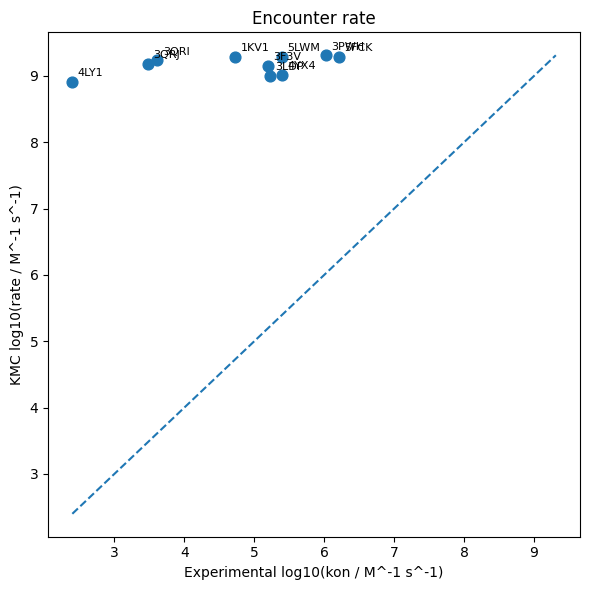

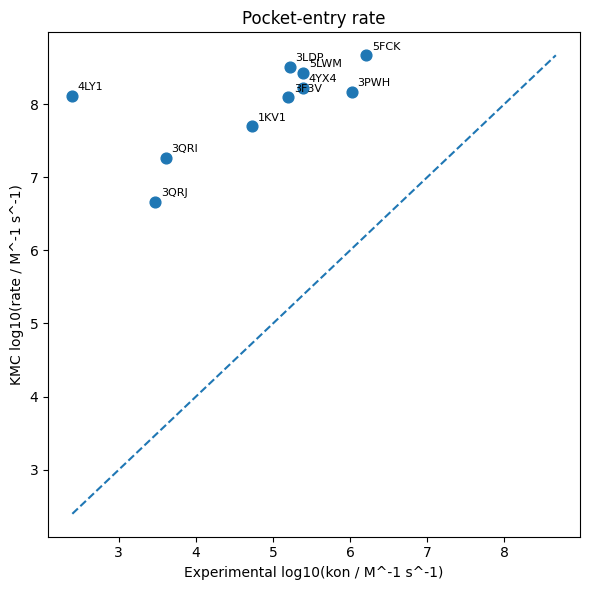

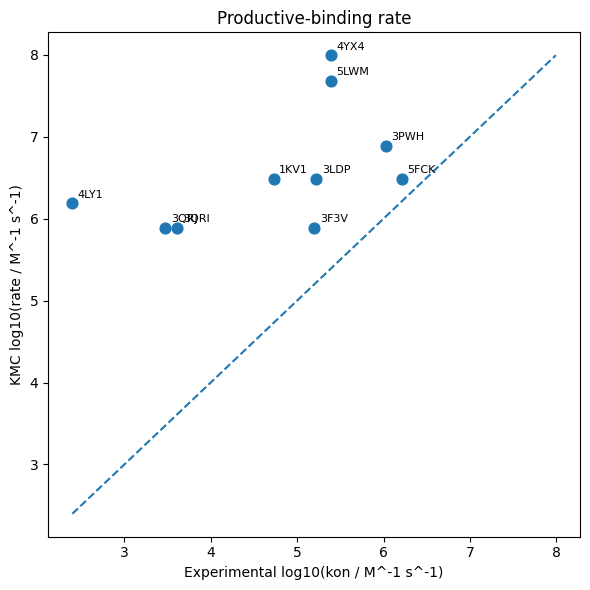

In [ ]:

if len(results) == 0:
    raise RuntimeError('No complexes completed successfully.')

# Zero-event simulations are left-censored. A half-event floor is used only
# for log-scale plotting and rank/error calculations.
volume_liter = (4.0 / 3.0) * math.pi * START_RADIUS_A**3 * 1e-27
concentration_M = 1.0 / (6.02214076e23 * volume_liter)
observation_time_s = MAX_STEPS * DT_NS * 1e-9
rate_floor = -math.log(1.0 - 0.5 / N_TRAJECTORIES) / (
    concentration_M * observation_time_s
)

for endpoint in ['k_encounter', 'k_entry', 'k_bound']:
    results[f'log10_{endpoint}'] = np.log10(
        results[endpoint].where(results[endpoint] > 0.0, rate_floor)
    )


def calculate_metrics(log_prediction_column, raw_endpoint):
    y = results['log10_kon_exp'].to_numpy()
    p = results[log_prediction_column].to_numpy()
    return {
        'endpoint': raw_endpoint,
        'n': len(y),
        'Pearson_r': pearsonr(y, p).statistic if len(y) >= 3 else np.nan,
        'Spearman_rho': spearmanr(y, p).statistic if len(y) >= 3 else np.nan,
        'MAE_log10': mean_absolute_error(y, p),
        'RMSE_log10': mean_squared_error(y, p)**0.5,
        'within_10_fold': float(np.mean(np.abs(y - p) <= 1.0)),
        'zero_event_fraction': float(np.mean(results[raw_endpoint] == 0.0)),
    }

metrics = pd.DataFrame([
    calculate_metrics('log10_k_encounter', 'k_encounter'),
    calculate_metrics('log10_k_entry', 'k_entry'),
    calculate_metrics('log10_k_bound', 'k_bound'),
])
metrics.to_csv(OUTPUTS / 'benchmark_metrics.csv', index=False)
display(metrics)

for prediction, title, filename in [
    ('log10_k_encounter', 'Encounter rate', 'encounter_rate_comparison.png'),
    ('log10_k_entry', 'Pocket-entry rate', 'entry_rate_comparison.png'),
    ('log10_k_bound', 'Productive-binding rate', 'bound_rate_comparison.png'),
]:
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(results['log10_kon_exp'], results[prediction], s=60)
    for _, item in results.iterrows():
        ax.annotate(
            item['pdb_id'],
            (item['log10_kon_exp'], item[prediction]),
            xytext=(4, 4), textcoords='offset points', fontsize=8
        )
    low = min(results['log10_kon_exp'].min(), results[prediction].min())
    high = max(results['log10_kon_exp'].max(), results[prediction].max())
    ax.plot([low, high], [low, high], '--')
    ax.set_xlabel('Experimental log10(kon / M^-1 s^-1)')
    ax.set_ylabel('KMC log10(rate / M^-1 s^-1)')
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(OUTPUTS / filename, dpi=200)
    plt.show()

results.to_csv(OUTPUTS / 'kmc_11_complex_results_with_logs.csv', index=False)


## 9. Per-complex error analysis

,complex_id,pdb_id,target,uniprot,kon_exp,k_encounter,k_entry,k_bound,log10_kon_exp,log10_k_encounter,...,n_entry,n_bound,minimum_rmsd,maximum_native_fraction,residual_encounter_log10,absolute_error_encounter_log10,residual_entry_log10,absolute_error_entry_log10,residual_bound_log10,absolute_error_bound_log10
7,KMC11_08,5FCK,Complement factor D,P00746,1.621622e+06,1.925455e+09,4.652381e+08,3.079468e+06,6.209950,9.284533,...,261,2,2.729066,0.579710,3.074584,3.074584,2.457726,2.457726,0.278526,0.278526
4,KMC11_05,3F3V,Src kinase,P00523,1.575342e+05,1.413283e+09,1.232494e+08,0.000000e+00,5.197375,9.150229,...,77,0,3.458552,0.395833,3.952854,3.952854,2.893410,2.893410,0.688715,0.688715
6,KMC11_07,3PWH,A2A adenosine receptor,P29274,1.059091e+06,2.048576e+09,1.484525e+08,7.710262e+06,6.024933,9.311452,...,92,5,2.255091,0.730769,3.286519,3.286519,2.146654,2.146654,0.862136,0.862136
8,KMC11_10,3LDP,Glucose-regulated protein,P11021,1.659751e+05,1.002911e+09,3.260300e+08,3.079468e+06,5.220043,9.001262,...,191,2,2.725483,0.660000,3.781219,3.781219,3.293215,3.293215,1.268433,1.268433
0,KMC11_01,1KV1,p38 alpha,Q16539,5.344828e+04,1.925455e+09,5.002698e+07,3.079468e+06,4.727934,9.284533,...,32,2,1.643889,0.631579,4.556600,4.556600,2.971271,2.971271,1.760542,1.760542
1,KMC11_02,3QRI,ABL1,P00519,4.097222e+03,1.728822e+09,1.856997e+07,0.000000e+00,3.612490,9.237750,...,12,0,7.898601,0.234375,5.625261,5.625261,3.656322,3.656322,2.273600,2.273600
9,KMC11_11,5LWM,JAK3,P52333,2.462687e+05,1.941675e+09,2.663592e+08,4.843875e+07,5.391409,9.288177,...,159,31,1.605651,0.636364,3.896767,3.896767,3.034059,3.034059,2.293784,2.293784
2,KMC11_03,3QRJ,ABL1,P00519,2.986111e+03,1.525201e+09,4.621518e+06,0.000000e+00,3.475106,9.183327,...,3,0,8.507919,0.179104,5.708221,5.708221,3.189679,3.189679,2.410984,2.410984
5,KMC11_06,4YX4,Carbonic anhydrase II,P00918,2.469697e+05,1.041779e+09,1.672008e+08,9.845261e+07,5.392644,9.017775,...,103,62,1.299898,0.705882,3.625132,3.625132,2.830595,2.830595,2.600584,2.600584
3,KMC11_04,4LY1,HDAC2,Q92769,2.500000e+02,8.194428e+08,1.299299e+08,1.538964e+06,2.397940,8.913519,...,81,1,2.097701,0.425532,6.515579,6.515579,5.715769,5.715769,3.789288,3.789288


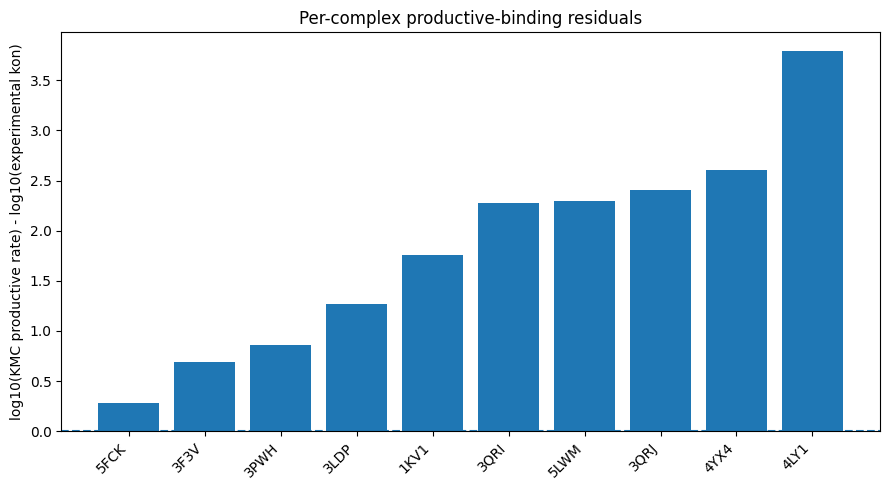

In [ ]:

comparison = results[[
    'complex_id','pdb_id','target','uniprot','kon_exp',
    'k_encounter','k_entry','k_bound',
    'log10_kon_exp','log10_k_encounter','log10_k_entry','log10_k_bound',
    'n_encounter','n_entry','n_bound','minimum_rmsd','maximum_native_fraction'
]].copy()

for endpoint in ['encounter','entry','bound']:
    comparison[f'residual_{endpoint}_log10'] = (
        comparison[f'log10_k_{endpoint}'] - comparison['log10_kon_exp']
    )
    comparison[f'absolute_error_{endpoint}_log10'] = (
        comparison[f'residual_{endpoint}_log10'].abs()
    )

comparison = comparison.sort_values('absolute_error_bound_log10')
comparison.to_csv(OUTPUTS / 'per_complex_comparison.csv', index=False)
display(comparison)

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(comparison))
ax.bar(x, comparison['residual_bound_log10'])
ax.axhline(0.0, linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels(comparison['pdb_id'], rotation=45, ha='right')
ax.set_ylabel('log10(KMC productive rate) - log10(experimental kon)')
ax.set_title('Per-complex productive-binding residuals')
plt.tight_layout()
plt.savefig(OUTPUTS / 'per_complex_bound_residuals.png', dpi=200)
plt.show()


## 10. Package persistent outputs

In [ ]:

summary = {
    "original_test_set_size": len(test_set),
    "single_component_test_set_size": len(test_set_kmc),
    "identified_native_ligands": len(identified),
    "runnable_systems": len(run_set),
    "successful_simulations": len(results),
    "failed_simulations": len(failures),
    "fast_mode": FAST_MODE,
    "trajectories_per_complex": N_TRAJECTORIES,
    "maximum_steps": MAX_STEPS,
    "approximate_time_per_step_ns": DT_NS,
    "persistent_project_directory": str(DRIVE_ROOT),
    "important_warning": (
        "FAST_MODE validates the workflow only and is not a publication-quality kinetic calculation."
        if FAST_MODE
        else
        "Production calculations still require replicate runs, convergence testing, uncertainty intervals, and model calibration."
    ),
}

(OUTPUTS / "RUN_SUMMARY.json").write_text(
    json.dumps(summary, indent=2)
)

archive = DRIVE_ROOT / "kmc_experimental_holo_outputs.zip"

with zipfile.ZipFile(
    archive,
    "w",
    zipfile.ZIP_DEFLATED,
) as zip_file:
    for path in OUTPUTS.glob("*"):
        zip_file.write(path, path.name)

print("Persistent output archive:", archive)
print("Archive size:", archive.stat().st_size / 1e6, "MB")


Persistent output archive: /content/drive/MyDrive/KMC_experimental_holo_benchmark/kmc_experimental_holo_outputs.zip
Archive size: 0.43906 MB



## How to resume after a Colab disconnect

1. Reopen the notebook.
2. Run the installation, import, configuration, test-set, structure-preparation,
   and KMC-definition cells.
3. Run the persistent benchmark cell again.

The benchmark reads JSON checkpoints from Google Drive. A complex with
`status="ok"` is skipped. A complex with `status="running"` was interrupted and
is rerun. A failed complex is retried when `RETRY_FAILED=True`.

Persistent files are stored under:

```text
MyDrive/KMC_experimental_holo_benchmark/
├── checkpoints/
├── trajectories/
├── structures/
├── ccd/
└── outputs/
```

PDB 5A3O remains documented in the original 11-entry table but is excluded from
the current single-component KMC calculation.
